# 02 — Phase 2: Clustering ngày

Phase 2 — Clustering ngày theo mẫu phát điện (`scripts/clustering.py`).

Đặc trưng ngày: năng lượng/kW, công suất đỉnh/kW, số giờ nắng, bức xạ trung bình ban ngày, nhiệt độ, độ biến động. K-Means + GMM, k = 2–6, chọn k bằng silhouette (K-Means) và BIC (GMM).

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Thư mục gốc của repo (notebook nằm trong notebooks/)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print("Repo root:", ROOT)
print("Python:", sys.executable)

Repo root: /home/hatch/workspace/data-mining-project/repo
Python: /home/hatch/workspace/data-mining-project/.venv/bin/python


In [2]:
# Chạy script tương ứng (dùng đúng Python của kernel này)
import subprocess
r = subprocess.run([sys.executable, str(ROOT / "scripts" / "clustering.py")],
                   capture_output=True, text=True)
print(r.stdout[-3000:])
print(r.stderr[-1000:] if r.returncode else "OK, exit 0")
assert r.returncode == 0, "script chạy lỗi, xem stderr ở trên"

System 4: k K-Means=2 (silhouette {2: 0.457, 3: 0.309, 4: 0.297, 5: 0.297, 6: 0.275}), k GMM theo BIC=6, cụm: [274, 91] ngày
System 1278: k K-Means=2 (silhouette {2: 0.445, 3: 0.323, 4: 0.307, 5: 0.279, 6: 0.322}), k GMM theo BIC=5, cụm: [214, 151] ngày
System 1403: k K-Means=2 (silhouette {2: 0.349, 3: 0.31, 4: 0.294, 5: 0.309, 6: 0.303}), k GMM theo BIC=5, cụm: [251, 114] ngày
Report: outputs/clustering_report.json

OK, exit 0


## 1. Chọn k: silhouette cao nhất ở k = 2 cho cả 3 hệ

In [3]:
import json
rep = json.load(open(ROOT / "outputs/clustering_report.json"))
for r in rep:
    km = {x["k"]: round(x["silhouette"], 3) for x in r["kmeans"]}
    print(f"System {r['system_id']}: k đã chọn (K-Means) = {r['chosen_k_kmeans']}, "
          f"silhouette theo k = {km}, GMM tốt nhất theo BIC: k = {r['chosen_k_gmm_by_bic']}")

System 4: k đã chọn (K-Means) = 2, silhouette theo k = {2: 0.457, 3: 0.309, 4: 0.297, 5: 0.297, 6: 0.275}, GMM tốt nhất theo BIC: k = 6
System 1278: k đã chọn (K-Means) = 2, silhouette theo k = {2: 0.445, 3: 0.323, 4: 0.307, 5: 0.279, 6: 0.322}, GMM tốt nhất theo BIC: k = 5
System 1403: k đã chọn (K-Means) = 2, silhouette theo k = {2: 0.349, 3: 0.31, 4: 0.294, 5: 0.309, 6: 0.303}, GMM tốt nhất theo BIC: k = 5


## 2. Hồ sơ từng cụm (trung bình theo cụm)

In [4]:
for sid in [4, 1278, 1403]:
    f = pd.read_csv(ROOT / f"data/processed/system_{sid}_2015_daily_features.csv")
    print(f"--- System {sid} ---")
    print(f.groupby("kmeans_cluster")[["energy_kwh_per_kw", "poa_daytime_mean",
          "daytime_hours", "ambient_temp_mean"]].mean().round(2))
    print("Số ngày mỗi cụm:", f["kmeans_cluster"].value_counts().sort_index().to_dict())

--- System 4 ---
                energy_kwh_per_kw  poa_daytime_mean  daytime_hours  \
kmeans_cluster                                                       
0                            4.81            571.57          10.81   
1                            1.32            256.17           8.51   

                ambient_temp_mean  
kmeans_cluster                     
0                           14.50  
1                            2.74  
Số ngày mỗi cụm: {0: 274, 1: 91}
--- System 1278 ---
                energy_kwh_per_kw  poa_daytime_mean  daytime_hours  \
kmeans_cluster                                                       
0                            5.16            692.23          12.27   
1                            2.75            521.07           9.11   

                ambient_temp_mean  
kmeans_cluster                     
0                           27.25  
1                           12.05  
Số ngày mỗi cụm: {0: 214, 1: 151}
--- System 1403 ---
                energy_kwh

## 3. Biểu đồ: elbow + silhouette (trái) và ngày theo cụm (phải)

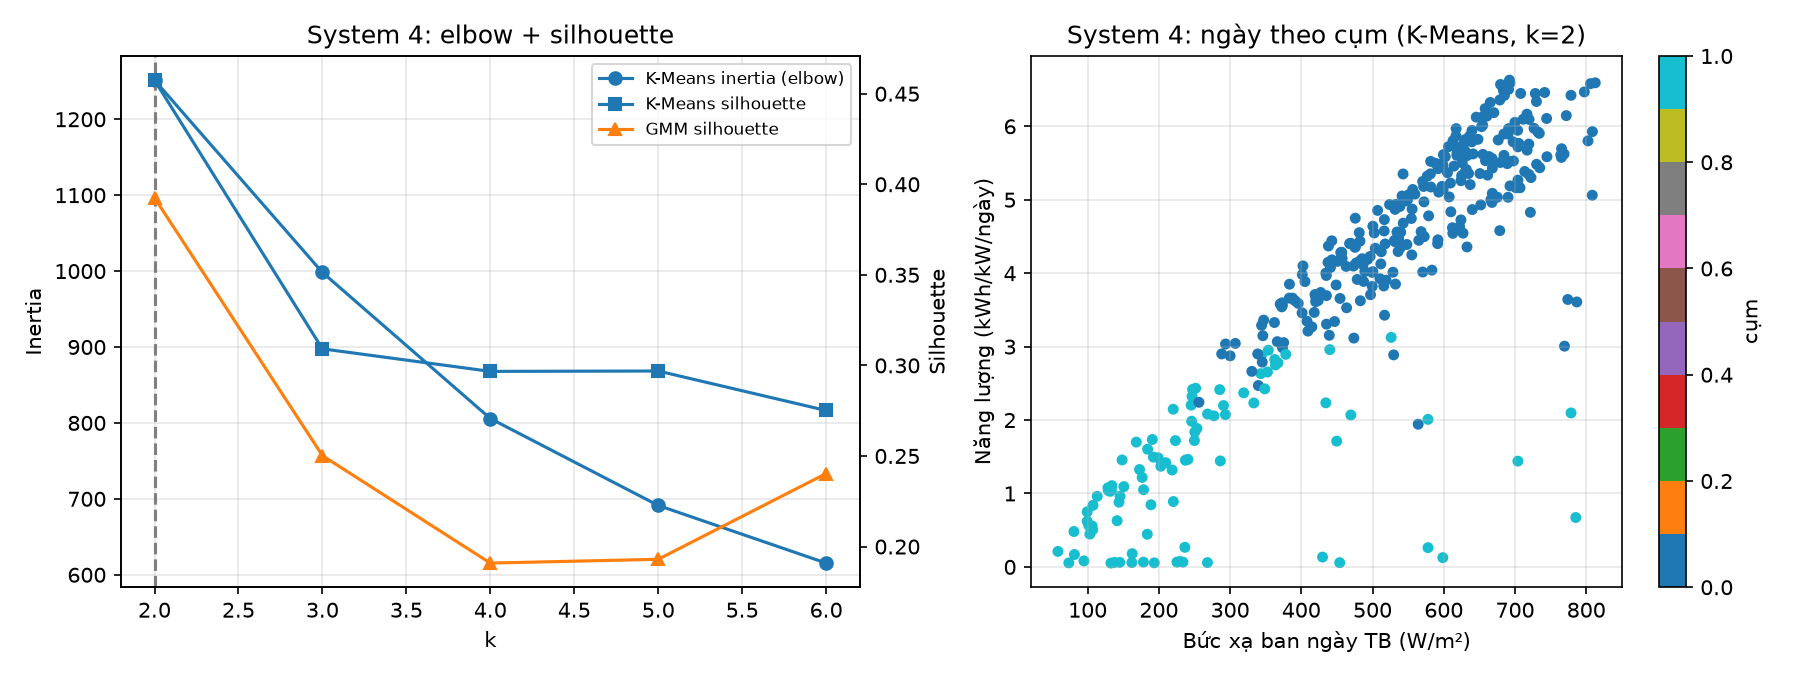

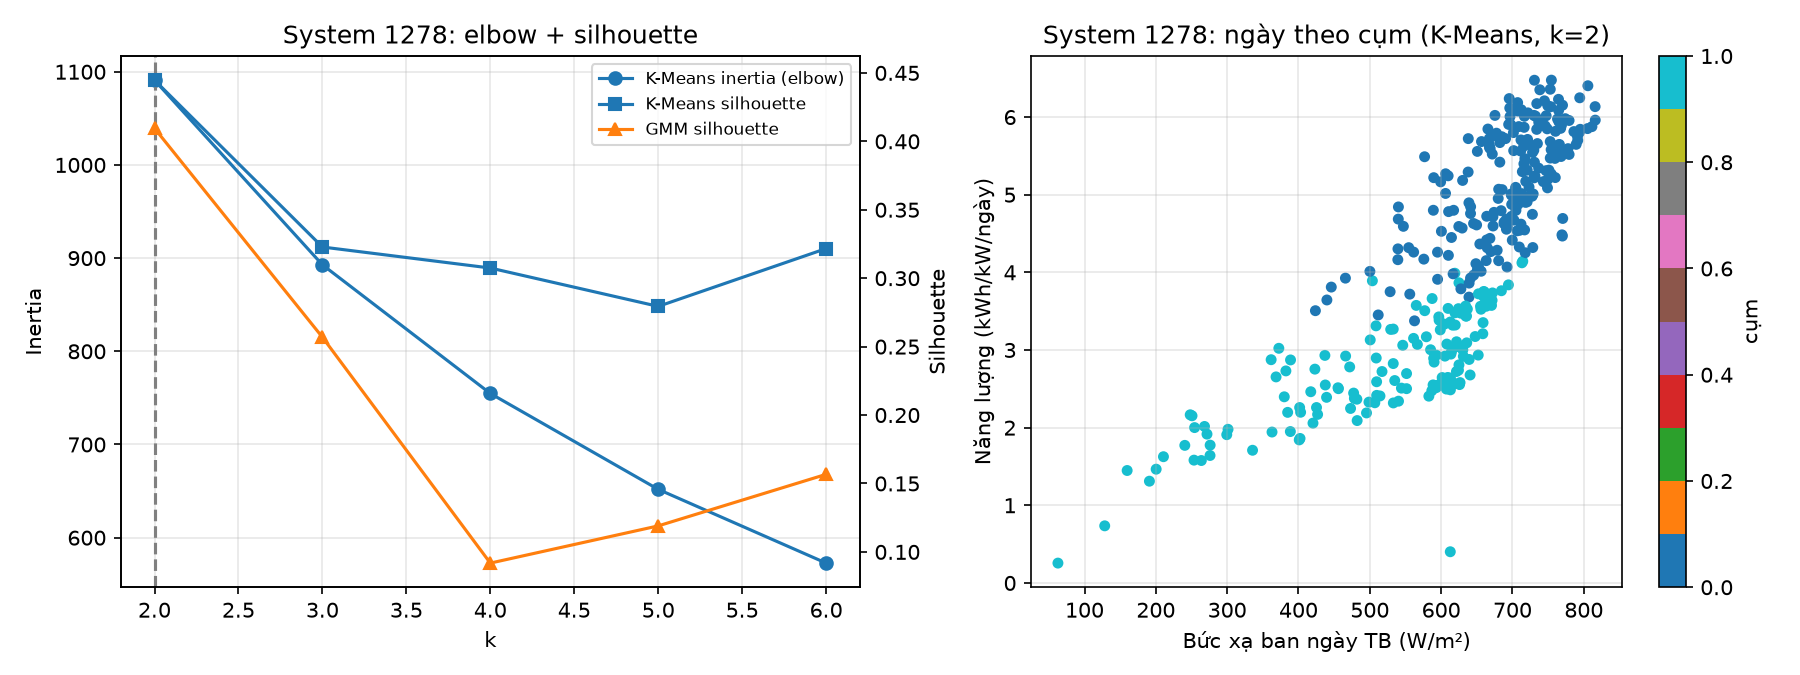

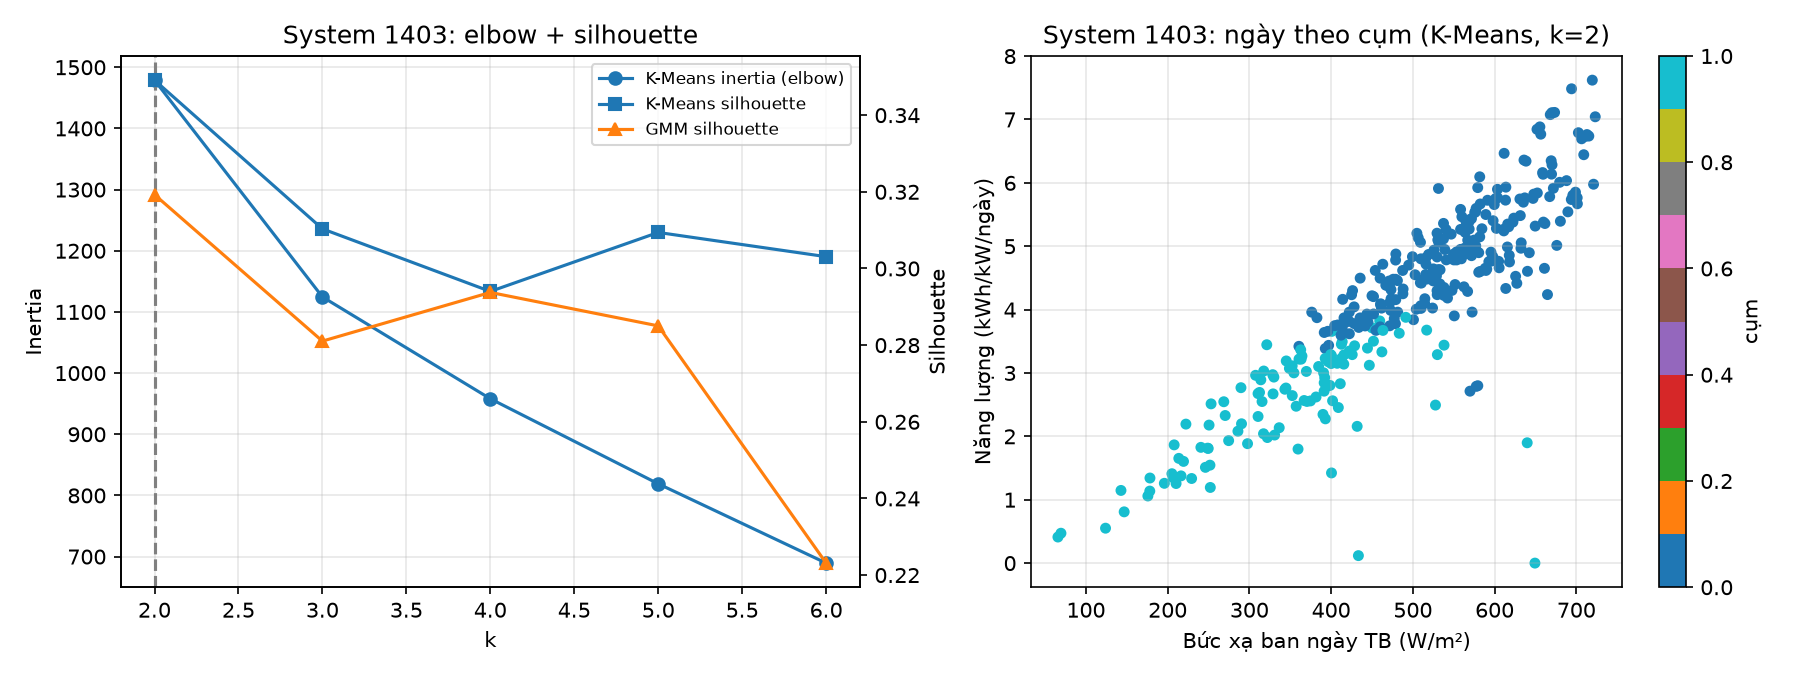

In [5]:
from IPython.display import Image, display
for sid in [4, 1278, 1403]:
    display(Image(filename=str(ROOT / f"outputs/clustering_system_{sid}.png"),
                  width=900))

**Đọc biểu đồ:** cụm xanh đậm = ngày nắng tốt (năng lượng cao), cụm xanh nhạt = ngày xấu. Ở Las Vegas 2 cụm tách gần như theo mùa (cao ≈ Mar–Oct, thấp ≈ Nov–Feb); ở Golden và Cocoa Beach cụm thấp rải cả năm, do mây.